# Projekt 2A – Raport 3: implementacja, testy programu, uczenie i walidacja

Kalina Staniszewska, Agnieszka Michałowska

Notatnik odtwarza wszystkie tabele i wykresy Raportu 3 z plików zapisanych podczas eksperymentów. **Niczego nie trenuje** i **nie używa zbioru testowego**: wszystkie metryki dotyczą zbioru walidacyjnego. Treningi uruchamiałyśmy z terminala skryptem `run_experiments.py` (bloki A–E, 640 treningów), a testy programu skryptem `test_programu.py`.

| Sekcja | Zawartość | Wymaganie |
| --- | --- | --- |
| 4 | środowisko, testy programu, architektury i ustawienia uczenia | Etap 3, Raport 2A |
| 5 | krzywe uczenia i ocena przeuczenia, czas uczenia i inferencji | Raport 2A |
| 6 | porównanie z modelami bazowymi na walidacji (blok A), prognozy walidacyjne | Raport 3A |
| 7 | długość okna, zmienne pomocnicze, architektura, TCN (bloki B–E) i zamrożenie konfiguracji | Raport 1, punkt 12.5 |

Wymagane pliki w folderze projektu: `ts_data.py`, `ts_models.py`, `ts_raport3.py`, folder `data` (pliki `prepared_*.pkl`), `outputs/eksperymenty` (wyniki, historie, prognozy walidacyjne) oraz `outputs/testy/testy_programu.csv`.

In [1]:
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import display

import ts_data as td
import ts_models as tm
import ts_raport3 as r3

warnings.filterwarnings("ignore")
td.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

OUT = tm.OUT                         # outputs/eksperymenty
FIG = Path("outputs/raport3")        # tu zapisujemy tabele (tables/) i rysunki (figures/) do raportu
df, bl = r3.load(OUT)
print(f"Treningi sieci: {len(df)}; wiersze modeli bazowych: {len(bl)}")
print(df.groupby("block").size().to_dict())

Treningi sieci: 640; wiersze modeli bazowych: 73
{'A': 261, 'B': 313, 'C': 27, 'D': 30, 'E': 9}


## 4. Implementacja i testy programu

### 4.1. Środowisko obliczeniowe

In [2]:
import json
env = json.load(open(OUT / "srodowisko.json", encoding="utf-8"))
display(pd.Series(env, name="wartość").to_frame())

,wartość
Python,3.12.10
TensorFlow,2.21.0
Keras,3.15.1
numpy,2.5.4
pandas,3.1.0
scikit-learn,1.9.1
system,Windows-11-10.0.26200-SP0
procesor,"Intel64 Family 6 Model 170 Stepping 4, GenuineIntel"
rdzenie,22
RAM [GB],31.6


**Komentarz.** Wszystkie treningi wykonałyśmy na jednym laptopie (Windows 11, procesor Intel z 22 wątkami, 31,6 GB RAM, bez GPU), w jednym procesie, więc czasy różnych modeli są porównywalne. Wersje bibliotek: Python 3.12.10, TensorFlow 2.21.0, Keras 3.15.1.

### 4.2. Testy programu

In [3]:
tests = r3.tests_table("outputs/testy/testy_programu.csv")
print(tests.status.value_counts().to_dict())
display(tests)

{'OK': 22}


,nr,obszar,dane,oczekiwany wynik,wynik,status
0,1,okna,"szereg 0, 1, ..., 199; (L, h) = (30, 1), (30, 6), (72, 24), (24, 12)",cel = ostatni krok wejscia + h; cale wejscie przed celem; liczba okien = T -...,"wszystkie 4 pary (L, h) zgodne",OK
1,2,okna,"szereg 0..99 z luka (NaN) w krokach 40-44; L = 10, h = 3","pomijane sa dokladnie okna, ktorych wejscie lub cel obejmuje luke; pozostale...",71 okien z 88; pominieto 17 przecinajacych luke,OK
2,3,okna,"szereg z etykietami train/val/test; L = 24, h = 6",przyklad nalezy do zbioru wg czasu celu; wejscie moze siegac do konca poprze...,"train/val/test: 151/60/60 okien, przypisanie zgodne",OK
3,4,podzial,4 zbiory (prawdziwe dane po przygotowaniu),zbiory rozlaczne i uporzadkowane w czasie; udzialy 60/20/20 (z dokladnoscia ...,jena: 42071/14016/14041; household: 20742/6912/6935; metro: 31527/10512/1051...,OK
4,5,skalowanie,szereg syntetyczny; wartosci val i test zmienione o +1000,parametry skalera = srednia i odchylenie z train; zmiana val/test nie zmieni...,srednia y z train = 5.1546 w obu wariantach,OK
5,6,skalowanie,"4 zbiory, wariant jednowymiarowy (prawdziwe dane)",srednia standaryzowanego targetu na train = 0 i odchylenie = 1 (z dokladnosc...,jena: +9.7e-17 / 1.000000; household: +1.1e-17 / 1.000000; metro: -3.1e-17 /...,OK
6,7,agregacja,"syntetyczne pomiary minutowe Household 00:01-03:00, moc = numer minuty","krok 01:00 = srednia z minut (00:00, 01:00], tzn. 00:01-01:00; etykieta = ko...","01:00 -> 30.5 (srednia minut 1-60), 02:00 -> 90.5",OK
7,8,braki,"szereg z lukami 1, 3 i 4 kroki",luki <= 3 uzupelnione ostatnia znana wartoscia; luka 4 krokow pozostaje w ca...,luka 1 i 3 krokow: ostatnia wartosc; luka 4 krokow: brak,OK
8,9,modele bazowe,"szereg y_t = t (0..199); h = 1, 6, 24; s = 24 i 168","persistence: y(t+h) prognozowane jako y(t); seasonal naive: y(t+h-s(k+1)), k...",zgodne z recznym obliczeniem dla 3 horyzontow i 2 okresow,OK
9,10,modele bazowe,"prawdziwe dane, wspolny zbior oceny walidacyjnej (Jena, h = 1)",MAE persistence z funkcji = MAE policzone recznie z y(t+h) - y(t),MAE = 0.6555 degC (n = 13832),OK


**Komentarz.** Wszystkie 22 testy kończą się wynikiem OK. Testy sprawdzają m.in., że okna nie zawierają informacji z przyszłości, że przykład trafia do zbioru według czasu celu, że skaler korzysta wyłącznie ze zbioru uczącego, że persistence i metryki zgadzają się z obliczeniem ręcznym, że przekształcenia odwrotne (standaryzacja, logarytm, różnice sezonowe) odtwarzają oryginalne wartości, że wznawianie pomija tylko kompletne przebiegi, że zbioru testowego nie da się użyć bez potwierdzenia, że trening z tym samym ziarnem jest powtarzalny oraz że zamrożonych konfiguracji nie da się przypadkowo nadpisać.

### 4.3. Architektury i liczba parametrów

In [4]:
r3.model_summaries()   # model.summary() z Keras dla konfiguracji bazowych (okno 72, 1 zmienna)

=== Dense ===


Model: "Dense_64x1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 72, 1)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 72)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           4,672 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,785 (26.50 KB)

 Trainable params: 6,785 (26.50 KB)

 Non-trainable params: 0 (0.00 B)

... (14 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 72, 1)             │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d (Conv1D)               │ (None, 72, 25)            │             100 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 72, 25)            │               0 │ conv1d[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_1 (Conv1D)             │ (None, 72, 25)            │           1,900 │ dropout[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (None, 72, 25)            │               0 │ conv1d_1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_2 (Conv1D)             │ (None, 72, 25)            │              50 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 72, 25)            │               0 │ dropout_1[0][0],           │
│                               │                           │                 │ conv1d_2[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 72, 25)            │               0 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_3 (Conv1D)             │ (None, 72, 25)            │           1,900 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_2 (Dropout)           │ (None, 72, 25)            │               0 │ conv1d_3[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_4 (Conv1D)             │ (None, 72, 25)            │           1,900 │ dropout_2[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_3 (Dropout)           │ (None, 72, 25)            │               0 │ conv1d_4[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_1 (Add)                   │ (None, 72, 25)            │               0 │ dropout_3[0][0],           │
│                               │                           │                 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_1 (Activation)     │ (None, 72, 25)            │               0 │ add_1[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_5 (Conv1D)             │ (None, 72, 25)            │           1,900 │ activation_1[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_4 (Dropout)           │ (None, 72, 25)            │               0 │ conv1d_5[0][0]             │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 17,276 (67.48 KB)

 Trainable params: 17,276 (67.48 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
arch = r3.architecture_table(df, FIG)
display(arch)
display(r3.training_settings())

,model,jednostki/filtry,warstwy,okno L,wejście,zbiory,parametry,opis
0,Dense,–,2,24,1 zmienna,Air Passengers,3 713,"Flatten → Dense(64, ReLU) → Dense(32, ReLU) → Dense(1)"
1,Dense,–,2,72,1 zmienna,"Household Power Consumption, Jena Climate, Metro Interstate Traffic Volume",6 785,"Flatten → Dense(64, ReLU) → Dense(32, ReLU) → Dense(1)"
4,GRU,64,1,12,1 zmienna,"Air Passengers, Jena Climate",12 929,"GRU(u) → Dropout(0,2) → Dense(1)"
7,GRU,64,1,168,1 zmienna,"Jena Climate, Metro Interstate Traffic Volume",12 929,"GRU(u) → Dropout(0,2) → Dense(1)"
5,GRU,64,1,24,1 zmienna,"Air Passengers, Jena Climate",12 929,"GRU(u) → Dropout(0,2) → Dense(1)"
3,GRU,64,1,6,1 zmienna,Air Passengers,12 929,"GRU(u) → Dropout(0,2) → Dense(1)"
9,GRU,128,1,72,1 zmienna,Jena Climate,50 433,"GRU(u) → Dropout(0,2) → Dense(1)"
2,GRU,32,1,72,1 zmienna,Jena Climate,3 393,"GRU(u) → Dropout(0,2) → Dense(1)"
6,GRU,64,1,72,1 zmienna,"Household Power Consumption, Jena Climate, Metro Interstate Traffic Volume",12 929,"GRU(u) → Dropout(0,2) → Dense(1)"
8,GRU,64,2,72,1 zmienna,Jena Climate,37 889,"GRU(u) → Dropout(0,2) → Dense(1)"


,ustawienie,wartość
0,Funkcja straty,MSE na standaryzowanym celu (Air: na przekształconym celu)
1,Optymalizator,Adam
2,Współczynnik uczenia,"0.001 (blok D: także 0,0003)"
3,Rozmiar partii,256 (Air Passengers: 16)
4,Maksymalna liczba epok,100
5,Wczesne zatrzymanie,"monitor val_loss, cierpliwość 10 epok, przywrócenie najlepszych wag"
6,Kolejność przykładów,mieszanie okien zbioru uczącego co epokę (shuffle=True)
7,Ziarna losowości,"42, 43, 44 (Air Passengers: 42–51)"
8,Ustawianie ziarna,"keras.utils.set_random_seed (Python, NumPy, TensorFlow) przed każdym treningiem"
9,Wybór konfiguracji,najmniejsze średnie MAE z ziaren na walidacji


**Komentarz.** Konfiguracja bazowa sieci rekurencyjnych to jedna warstwa z 64 jednostkami, dropout 0,2 i liniowe wyjście: LSTM ma 16 961 parametrów, GRU 12 929 (o 24% mniej). Dense ma 6785 parametrów przy oknie 72 h i 3713 przy oknie 24 miesięcy, bo jego pierwsza warstwa łączy się z każdym krokiem okna; liczba parametrów LSTM i GRU nie zależy od długości okna. TCN (blok E) ma 17 276 parametrów, czyli prawie tyle co LSTM, co pozwala porównać rodziny modeli przy podobnej pojemności. Zmienne pomocnicze (blok C) zwiększają liczbę parametrów LSTM do 18 497–22 337, zależnie od liczby cech wejściowych.

## 5. Uczenie: krzywe straty, przeuczenie i koszt obliczeniowy

### 5.1. Krzywe uczenia (blok A, horyzont środkowy)

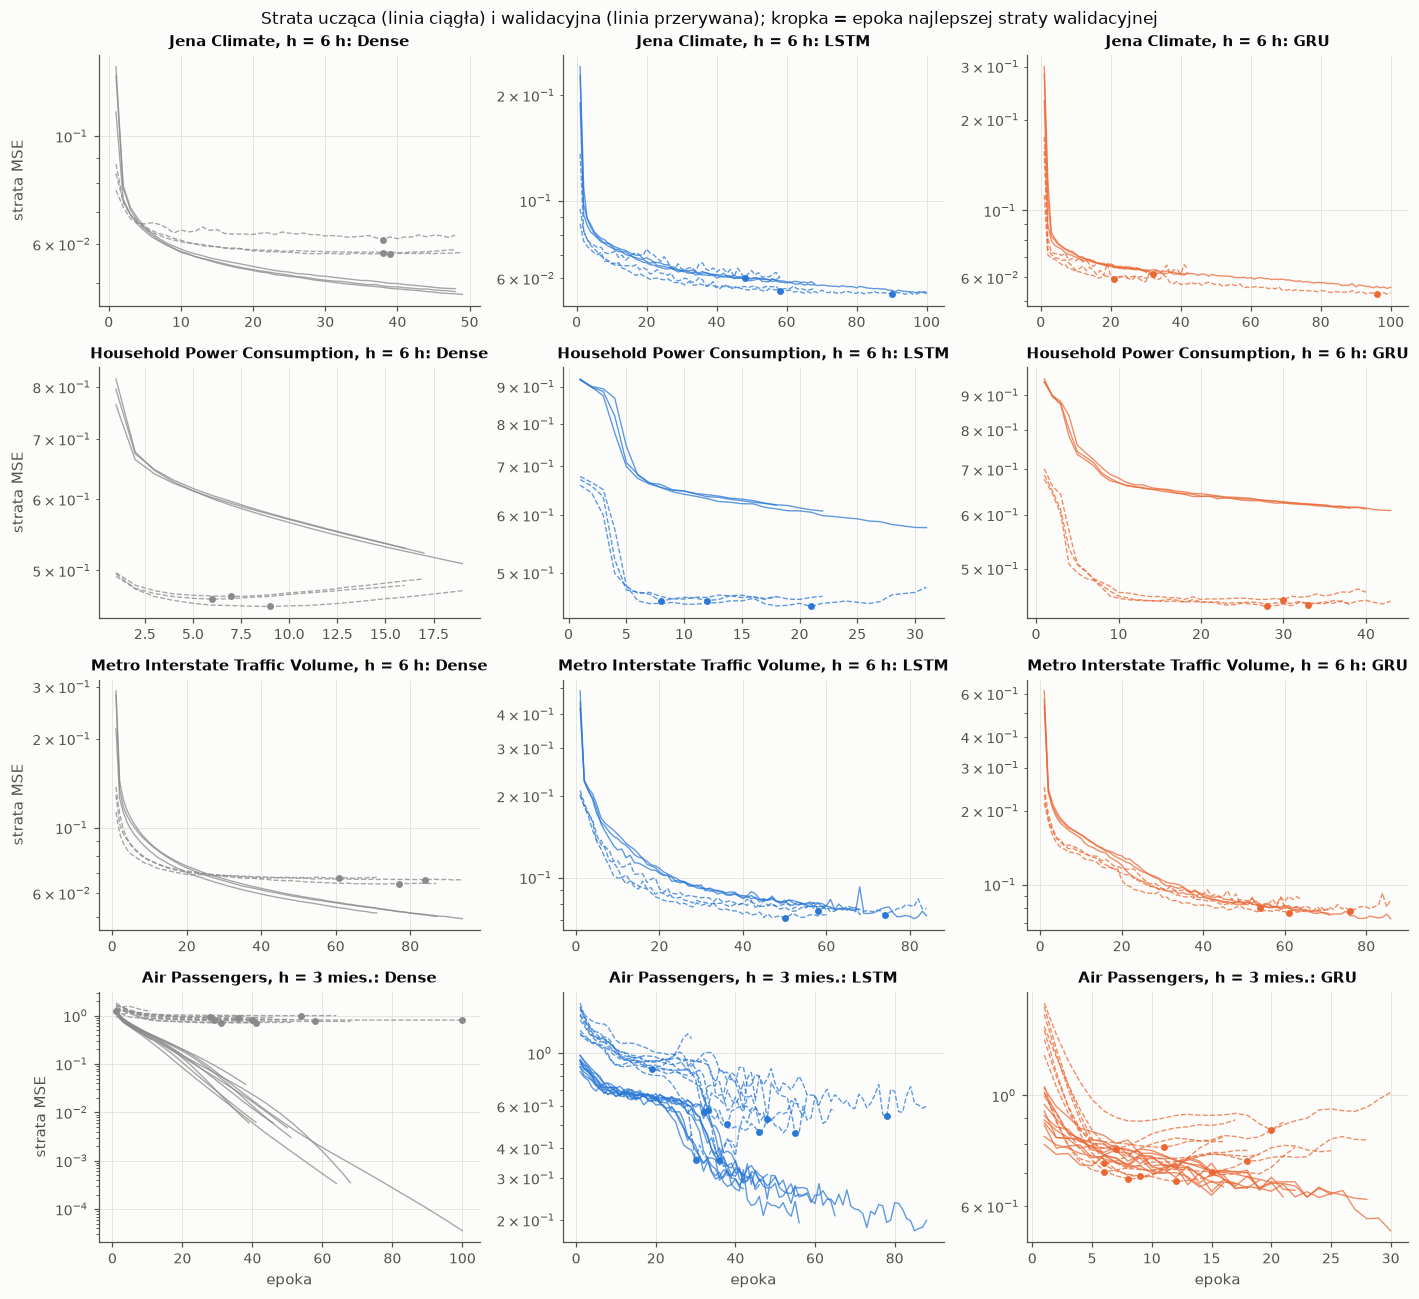

In [6]:
fig = r3.plot_curves_grid(df, OUT, FIG)

**Komentarz.** Rysunek pokazuje stratę uczącą i walidacyjną dla wszystkich ziaren przy horyzoncie środkowym (6 h, dla Air Passengers 3 miesiące, wariant sdiff).

- **Jena Climate i Metro:** obie straty maleją razem, a strata walidacyjna stabilizuje się na poziomie zbliżonym do uczącej. Nie widać przeuczenia; wczesne zatrzymanie kończy uczenie, gdy poprawa ustaje.
- **Household:** strata walidacyjna jest wyraźnie *niższa* od uczącej. Nie jest to błąd: dane walidacyjne mają mniejszy rozrzut niż uczące (Raport 2, tabela rozkładu), a w trakcie uczenia działa dropout. Strata walidacyjna osiąga minimum po kilku–kilkunastu epokach (Dense i LSTM), a potem lekko rośnie, co jest pierwszym sygnałem przeuczenia; wczesne zatrzymanie przywraca wagi z minimum.
- **Air Passengers:** Dense wyraźnie się przeucza: strata ucząca spada o trzy rzędy wielkości, a walidacyjna stoi w miejscu. LSTM i GRU też mają dużą lukę między stratami i silny rozrzut między ziarnami. Przy 49–72 przykładach uczących jest to spodziewane.

### 5.2. Ocena przeuczenia (wszystkie treningi)

In [7]:
ov = r3.overfit_summary(df, OUT, FIG)
display(ov.round(2))

,key,model,treningi,epoki,najlepsza,limit,val_train,wzrost_val,MAE_val_train
6,jena,Dense,9,46.78,36.78,0,1.15,1.31,1.03
8,jena,LSTM,61,49.84,40.43,6,0.94,1.48,1.01
7,jena,GRU,51,62.51,53.47,7,0.95,1.15,1.01
9,jena,TCN,9,65.56,56.78,2,0.96,0.57,1.02
3,household,Dense,9,17.78,7.78,0,0.78,3.58,0.92
5,household,LSTM,18,25.89,15.89,0,0.75,3.51,0.92
4,household,GRU,9,41.44,31.44,0,0.71,1.14,0.87
10,metro,Dense,9,57.67,47.67,0,0.92,0.50,0.95
12,metro,LSTM,27,52.93,42.93,0,0.79,5.34,0.93
11,metro,GRU,18,65.39,55.39,0,0.75,5.36,0.89


**Komentarz.** Kolumny: średnia liczba epok i epoka najlepszej straty walidacyjnej, liczba treningów zakończonych na limicie 100 epok, mediana stosunku strat val/train w najlepszej epoce, mediana wzrostu straty walidacyjnej od minimum do końca uczenia (w %) oraz mediana stosunku MAE walidacyjnego do uczącego w oryginalnych jednostkach.

- Dla zbiorów godzinowych stosunek MAE val/train wynosi 0,87–1,03: modele nie są przeuczone. Wartości poniżej 1 dla Household i Metro wynikają z łatwiejszego okresu walidacyjnego, nie z niedouczenia.
- Air Passengers jest wyjątkiem: Dense ma błąd walidacyjny ok. 5 razy większy niż uczący, LSTM i GRU ok. 1,6–1,7 raza. Przy tak małym zbiorze o wyborze konfiguracji decyduje walidacja, a wyniki trzeba czytać ze sporym rozrzutem.
- Limit 100 epok osiągnęło 39 z 640 treningów (19 dla Air Passengers w wariancie log, 5 dla Air w wariancie sdiff i 15 dla Jena Climate, głównie z krótkim oknem). W tych przypadkach model mógłby się jeszcze poprawić; wszystkie konfiguracje mają jednak ten sam limit, więc porównanie jest uczciwe.

### 5.3. Czas uczenia, czas prognozy i pamięć

In [8]:
display(r3.cost_table(df, FIG).round(2))
display(r3.block_time_table(df, FIG).round(2))

,key,model,parametry,epoki,czas_treningu_s,s_na_epoke,inferencja_ms_1000,rozmiar_kb,pamiec_szczyt_mb,przyrost_pamieci_mb
6,jena,Dense,6785,46.78,10.68,0.23,43.37,109.2,563.40,34.9
8,jena,LSTM,16961,49.00,445.03,9.25,112.81,226.9,888.20,62.4
7,jena,GRU,12929,55.56,447.96,7.88,96.89,179.7,1059.30,55.5
9,jena,TCN,17276,65.56,531.95,6.33,80.02,330.7,1010.80,72.4
3,household,Dense,6785,17.78,2.95,0.17,42.81,109.2,1095.10,24.4
5,household,LSTM,16961,32.33,124.01,3.83,112.16,226.9,1240.90,35.2
4,household,GRU,12929,41.44,161.55,3.90,96.35,179.7,1385.00,37.7
10,metro,Dense,6785,57.67,9.56,0.17,46.70,109.2,1444.80,18.9
12,metro,LSTM,16961,58.44,218.78,3.75,109.41,226.9,1570.20,31.6
11,metro,GRU,12929,66.00,233.33,3.51,92.39,179.7,1709.30,36.3


,block,treningi,czas_h
0,A,261,4.34
1,B,313,10.00
2,C,27,1.41
3,D,30,4.73
4,E,9,1.33


**Komentarz.** Dane dla konfiguracji z bloku A (okno 72 h / 24 mies.) i TCN z bloku E. Czas inferencji to mediana czasu prognozy dla 1000 okien.

- Dense uczy się 20–40 razy szybciej niż LSTM i GRU (ok. 0,2 s na epokę wobec 3,5–9 s na zbiorach godzinowych) i prognozuje ok. 2,5 raza szybciej.
- GRU jest na epokę szybszy od LSTM na Jenie (7,9 wobec 9,3 s) i prognozuje szybciej na wszystkich zbiorach godzinowych (mediana ok. 92–97 wobec 109–113 ms na 1000 okien), ale często potrzebuje więcej epok, więc całkowity czas uczenia obu sieci jest podobny.
- TCN prognozuje szybciej niż obie sieci rekurencyjne (ok. 80 ms), bo sploty liczą wszystkie kroki okna równolegle.
- Szczytowe zużycie pamięci (RSS procesu) rośnie w trakcie całego bloku i opisuje proces, nie pojedynczy model; porównujemy więc przyrost pamięci w czasie treningu (12–72 MB).
- Łączny czas wszystkich treningów: ok. 21,8 h (A 4,3 h, B 10,0 h, C 1,4 h, D 4,7 h, E 1,3 h).

## 6. Porównanie z modelami bazowymi na walidacji (blok A)

Wszystkie modele w danej parze (zbiór, horyzont) są oceniane na tych samych chwilach prognozy (wspólny zbiór oceny), w oryginalnych jednostkach. Sieci: średnia ± odchylenie standardowe z ziaren (3, dla Air Passengers 10). Skill score = 1 − MAE / MAE persistence. Dla Air Passengers wariant przekształcenia (log albo sdiff) jest wybierany na walidacji osobno dla każdego modelu.

### Jena Climate

In [9]:
t = r3.block_a_table(df, bl, "jena", FIG)
display(r3.block_a_display(t, "jena"))

,h,model,MAE,RMSE,skill
0,1,persistence,0.655,0.931,0.000
1,1,seasonal naive,2.552,3.296,-2.893
2,1,regresja liniowa,0.404,0.592,0.384
3,1,Dense,0.472 ± 0.041,0.651,0.281 ± 0.063
4,1,LSTM,0.411 ± 0.002,0.595,0.373 ± 0.003
5,1,GRU,0.407 ± 0.002,0.590,0.380 ± 0.003
6,6,persistence,3.035,4.063,0.000
7,6,seasonal naive,2.552,3.297,0.159
8,6,regresja liniowa,1.687,2.219,0.444
9,6,Dense,1.638 ± 0.041,2.136,0.460 ± 0.014


### Household Power Consumption

In [10]:
t = r3.block_a_table(df, bl, "household", FIG)
display(r3.block_a_display(t, "household"))

,h,model,MAE,RMSE,MAPE [%],sMAPE [%],skill
0,1,persistence,0.419,0.637,46.5,38.5,0.000
1,1,seasonal naive,0.531,0.796,65.6,48.6,-0.268
2,1,regresja liniowa,0.377,0.535,48.6,37.9,0.101
3,1,Dense,0.381 ± 0.003,0.536,49.8,39.9,0.091 ± 0.008
4,1,LSTM,0.358 ± 0.002,0.516,45.0,35.2,0.147 ± 0.006
5,1,GRU,0.361 ± 0.007,0.520,45.2,35.8,0.140 ± 0.018
6,6,persistence,0.939,1.210,143.9,83.6,0.000
7,6,seasonal naive,0.531,0.795,65.5,48.6,0.435
8,6,regresja liniowa,0.501,0.673,74.8,51.2,0.466
9,6,Dense,0.492 ± 0.007,0.658,73.4,50.3,0.476 ± 0.007


### Metro Interstate Traffic Volume

In [11]:
t = r3.block_a_table(df, bl, "metro", FIG)
display(r3.block_a_display(t, "metro"))

,h,model,MAE,RMSE,sMAPE [%],skill
0,1,persistence,575,817.0,26.0,0.000
1,1,seasonal naive,339,628.0,14.8,0.410
2,1,regresja liniowa,295,445.0,14.6,0.488
3,1,Dense,215 ± 2,311.0,11.6,0.627 ± 0.004
4,1,LSTM,233 ± 16,344.0,11.7,0.594 ± 0.028
5,1,GRU,220 ± 8,324.0,11.1,0.617 ± 0.013
6,6,persistence,2339,2781.0,87.8,0.000
7,6,seasonal naive,340,628.0,14.8,0.855
8,6,regresja liniowa,569,864.0,26.3,0.757
9,6,Dense,325 ± 1,522.0,16.5,0.861 ± 0.000


### Air Passengers

In [12]:
t = r3.block_a_table(df, bl, "air", FIG)
display(r3.block_a_display(t, "air"))

,h,model,MAE,RMSE,MAPE [%],sMAPE [%],skill
0,1,persistence,35.9,44.0,9.5,9.5,0.000
1,1,seasonal naive,26.4,31.7,6.9,7.3,0.265
2,1,regresja liniowa (sdiff),8.9,11.8,2.4,2.4,0.751
3,1,Dense (sdiff),13.1 ± 2.3,16.4,3.6,3.5,0.635 ± 0.063
4,1,LSTM (sdiff),12.9 ± 0.8,16.9,3.6,3.5,0.640 ± 0.023
5,1,GRU (sdiff),9.2 ± 0.4,12.5,2.5,2.5,0.745 ± 0.011
6,3,persistence,71.6,89.7,19.1,18.3,0.000
7,3,seasonal naive,26.4,31.7,6.9,7.3,0.632
8,3,regresja liniowa (log),13.5,16.9,3.7,3.6,0.812
9,3,Dense (sdiff),17.7 ± 1.9,22.0,4.9,4.7,0.753 ± 0.026


**Komentarz.**

- **Jena Climate:** przy h = 1 LSTM i GRU (0,411 i 0,407 °C) są praktycznie równe regresji liniowej (0,404 °C); przy h = 6 LSTM ma MAE 1,595 °C wobec 1,687 °C regresji; przy h = 24 wszystkie modele uczone są blisko persistence (skill ok. 0,05), bo temperatura za dobę zależy głównie od zmian pogody, których sama historia temperatury nie zapowiada.
- **Household:** LSTM i GRU są najlepsze na wszystkich horyzontach, ale przewaga nad regresją liniową jest mała (np. h = 6: GRU 0,475 wobec 0,501 kW). Duże MAPE (45–75%) wynika z wartości bliskich zera w nocy, dlatego ważniejszy jest sMAPE.
- **Metro:** przy h = 1 i h = 6 najlepszy jest prosty Dense (215 i 325 pojazdów/h). Przy h = 24 wszystkie sieci przegrywają z seasonal naive (339 pojazdów/h): okno 72 h nie zawiera tej samej godziny sprzed tygodnia. Blok B sprawdza, czy pomaga dłuższe okno.
- **Air Passengers:** wariant sdiff jest lepszy od log dla wszystkich sieci. Przy h = 1 najlepsza jest regresja liniowa (8,9 tys.), przy h = 3 LSTM (13,2 tys.), przy h = 12 GRU (14,9 tys.), ale z rozrzutem między ziarnami 4,6–7,0 tys., czyli różnice między sieciami nie są wiarygodne.

### 6.1. Skill score w funkcji horyzontu

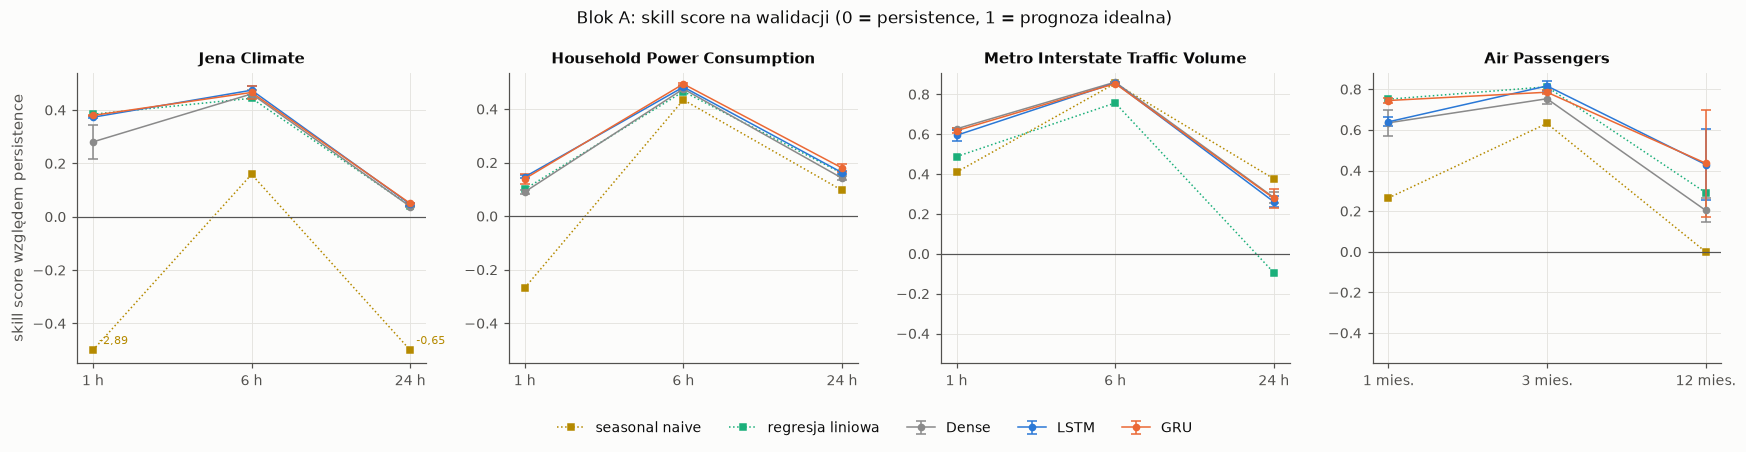

In [13]:
fig = r3.plot_skill(df, bl, FIG)

**Komentarz.** Na wszystkich zbiorach i horyzontach sieci mają dodatni skill score, czyli są lepsze od persistence. Najwięcej zyskują przy h = 6, gdzie persistence jest najsłabsza. Krzywe LSTM i GRU prawie się pokrywają, a regresja liniowa leży blisko nich wszędzie poza Metro (h = 6 i 24), gdzie jest wyraźnie gorsza. Seasonal naive ma dla Jena Climate skill −2,89 przy h = 1 i −0,65 przy h = 24 (oś przycięta; wartości podpisane).

### 6.2. Prognozy na fragmencie zbioru walidacyjnego

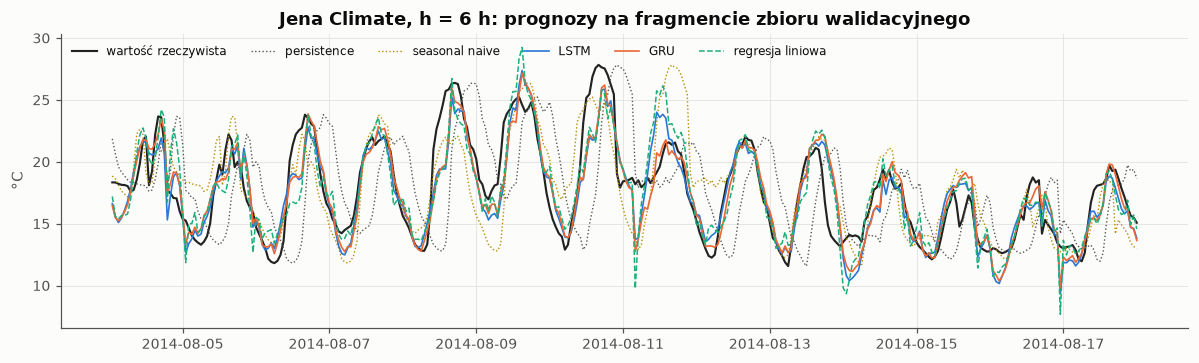

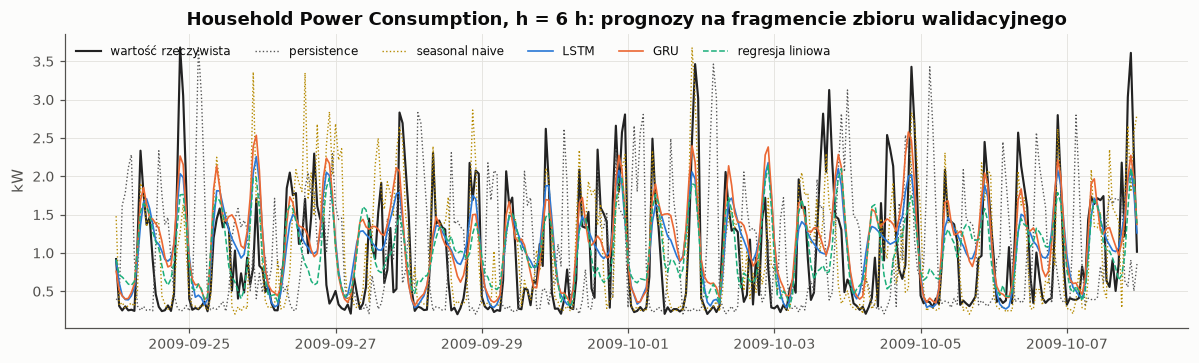

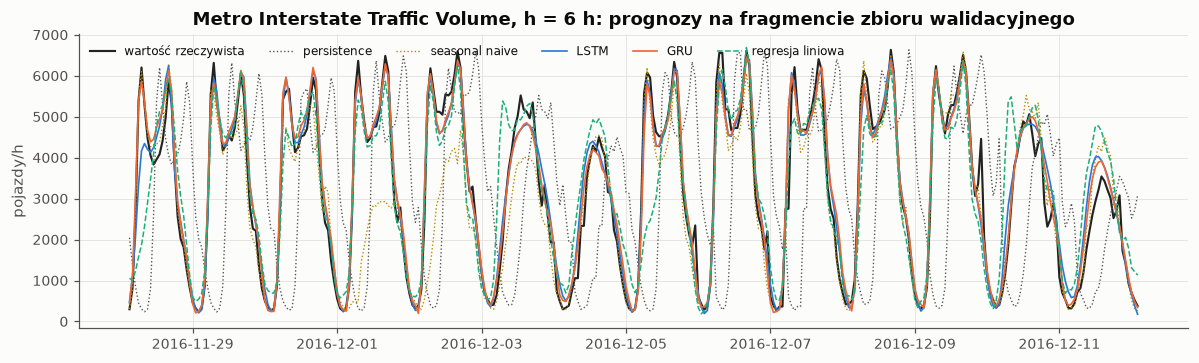

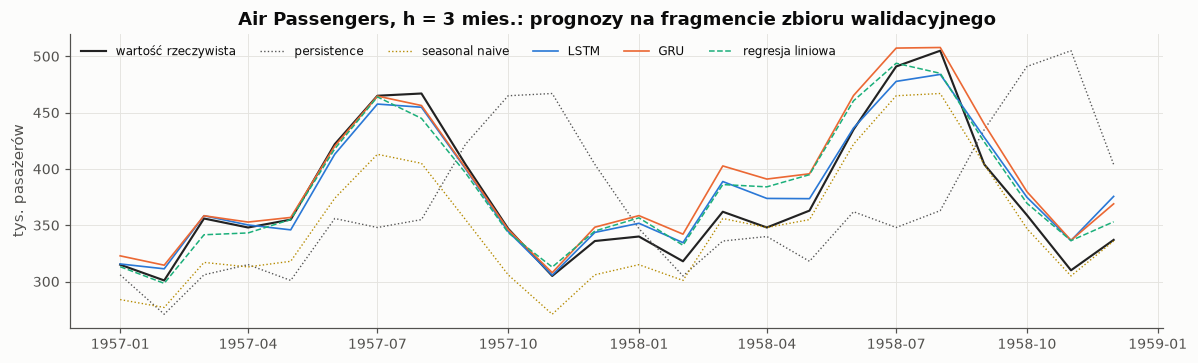

In [14]:
for key in tm.KEYS:
    fig = r3.val_forecast_figure(df, key, r3.MID_H[key], OUT, FIG)

**Komentarz.** Wykresy pokazują dwa tygodnie ze środka okresu walidacyjnego (Air Passengers: cały okres walidacyjny, 24 miesiące) dla horyzontu środkowego; linie kropkowane to persistence i seasonal naive, przerywana zielona to uczony model bazowy (regresja liniowa z tym samym oknem), a kolorowe to LSTM i GRU z ziarnem 42. Prognozy sieci odtwarzają cykl dobowy i tygodniowy, ale są gładsze niż rzeczywistość: nie przewidują nagłych zmian (np. skoków poboru mocy w Household), tylko przesuwają się za nimi. Dla Air Passengers prognozy śledzą sezonowość i poziom, mimo że poziom walidacyjny przekracza zakres zbioru uczącego, co potwierdza słuszność wariantu sdiff.

## 7. Bloki B–E i zamrożenie konfiguracji

### 7.1. Blok B: długość okna

,key,h,model,L,variant,n,MAE,MAE_sd,epoki,czas_s
56,air,1,GRU,6,sdiff,10,8.185,0.195,61.100,4.894
57,air,1,GRU,12,sdiff,10,9.779,0.620,31.900,3.083
58,air,1,GRU,24,sdiff,10,9.162,0.388,35.100,3.652
59,air,1,LSTM,6,sdiff,10,8.429,0.291,74.700,5.642
60,air,1,LSTM,12,sdiff,10,13.859,0.336,21.500,2.293
...,...,...,...,...,...,...,...,...,...,...
47,metro,24,GRU,168,std,3,339.939,7.418,56.667,470.940
48,metro,24,LSTM,72,std,3,401.515,14.745,47.333,173.097
49,metro,24,LSTM,168,std,3,335.706,8.976,48.667,368.383
54,metro,24,linreg,72,std,1,594.643,0.000,NaN,NaN


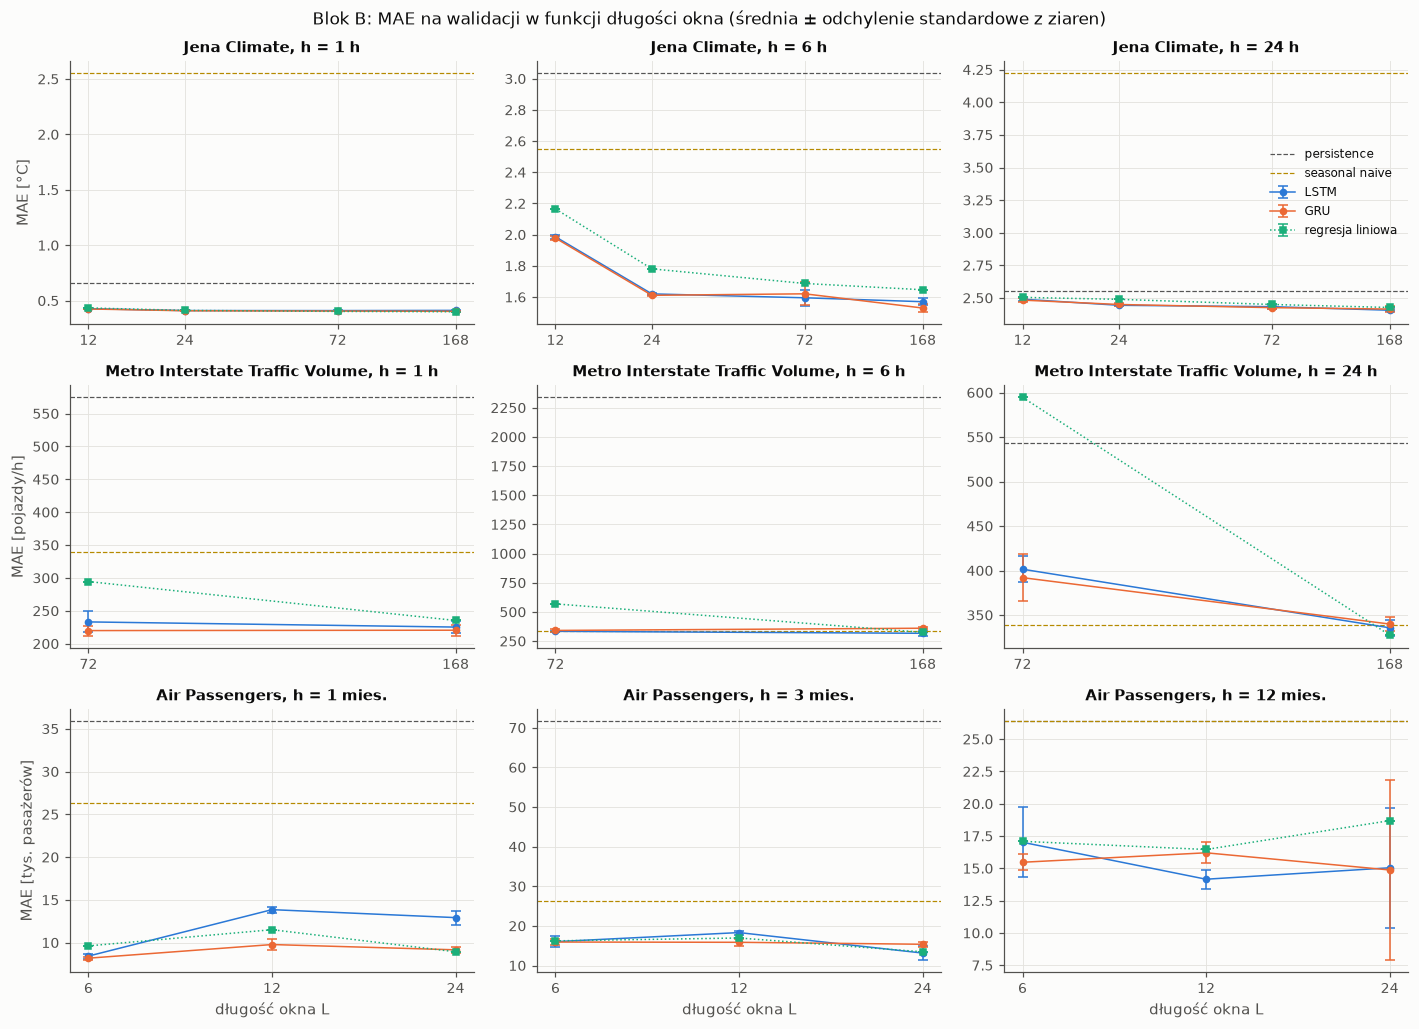

In [15]:
tb = r3.block_b_table(df, bl, FIG)
fig = r3.plot_block_b(tb, bl, FIG)
display(tb.round(3))

**Komentarz.**

- **Jena Climate:** najkrótsze okno 12 h jest wyraźnie gorsze (h = 6: ok. 1,98 °C), a od 24 h zysk szybko maleje; okno 168 h daje najmniejsze MAE dla GRU przy h = 6 (1,530 °C) i dla LSTM przy h = 24 (2,406 °C), ale uczenie trwa ok. 5 razy dłużej niż z oknem 24 h. Kontrolny przebieg z oknem 30 h (LSTM, h = 1) dał 0,407 °C, tyle co okna 24–72 h.
- **Metro:** okno 168 h, obejmujące tę samą godzinę tydzień wcześniej, obniża MAE przy h = 24 z ok. 400 do ok. 336–340 pojazdów/h, czyli do poziomu seasonal naive (339). Regresja liniowa z tym samym oknem jest jednak równie dobra (328 pojazdów/h).
- **Air Passengers:** wyniki są niestabilne i nie układają się w jeden kierunek; przy h = 1 najlepsze jest najkrótsze okno 6 miesięcy (GRU 8,2 tys.), przy h = 12 okno 12 miesięcy (LSTM 14,2 tys.).

### 7.2. Blok C: zmienne pomocnicze

,key,h,LSTM_uni,LSTM_uni_sd,linreg_uni,LSTM_multi,LSTM_multi_sd,linreg_multi,persistence,seasonal_naive,zmiana_LSTM_%,zmiana_linreg_%,wszystkie_ziarna_lepsze
0,jena,1,0.411,0.002,0.404,0.387,0.006,0.392,0.655,2.552,-5.906,-2.843,True
1,jena,6,1.595,0.051,1.687,1.461,0.011,1.527,3.035,2.552,-8.418,-9.467,True
2,jena,24,2.433,0.016,2.450,2.348,0.011,2.339,2.554,4.223,-3.496,-4.516,True
3,household,1,0.358,0.002,0.377,0.349,0.004,0.373,0.419,0.531,-2.271,-0.984,True
4,household,6,0.486,0.002,0.501,0.517,0.015,0.485,0.939,0.531,6.522,-3.262,False
5,household,24,0.493,0.003,0.495,0.525,0.008,0.490,0.590,0.533,6.290,-0.936,False
6,metro,1,233.140,16.026,294.526,210.051,1.048,268.596,574.782,339.366,-9.903,-8.804,True
7,metro,6,333.921,3.748,569.097,301.596,18.820,405.085,2339.362,339.729,-9.680,-28.820,True
8,metro,24,401.515,14.745,594.643,305.880,7.602,400.094,543.315,338.959,-23.819,-32.717,True


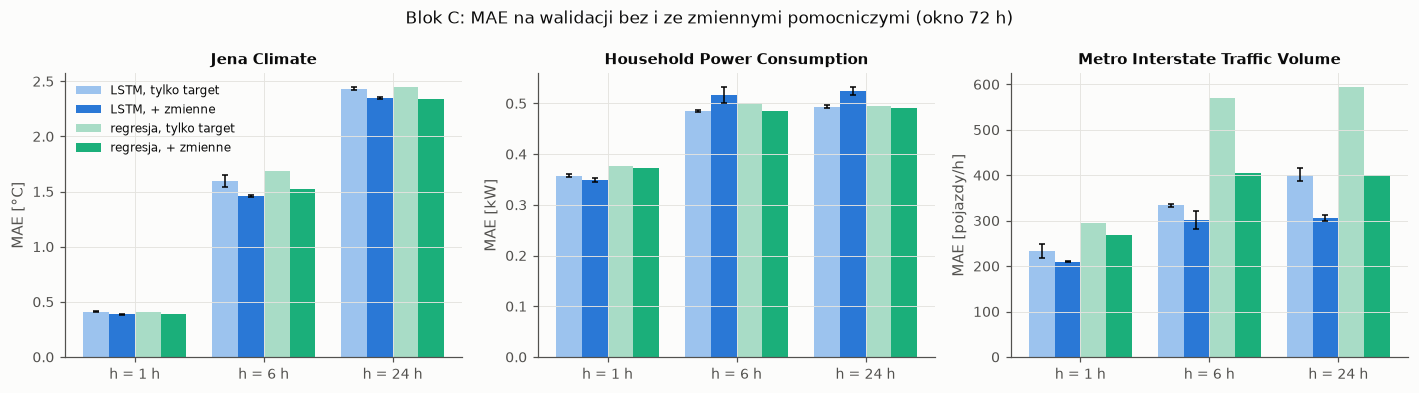

In [16]:
tc = r3.block_c_table(df, bl, FIG)
fig = r3.plot_block_c(tc, FIG)
display(tc.round(3))

**Komentarz.**

- **Metro:** zmienne kalendarzowe dla chwili prognozy dają największy zysk w projekcie: przy h = 24 MAE LSTM spada z 402 do 306 pojazdów/h (−24%), poniżej seasonal naive (339) i najlepszej regresji (328). To jedyny przypadek, w którym sieć rekurencyjna wyraźnie wygrywa ze wszystkimi modelami bazowymi.
- **Jena Climate:** zmienne pogodowe poprawiają LSTM na wszystkich horyzontach (o 3,5–8,4%) dla wszystkich ziaren, ale przy h = 24 regresja liniowa z tymi samymi zmiennymi jest równie dobra (2,339 wobec 2,348 °C).
- **Household:** zmienne pomocnicze pomagają tylko przy h = 1 (0,349 wobec 0,358 kW); przy h = 6 i 24 LSTM jest o ok. 6,5% gorszy niż bez nich, choć regresja liniowa z tymi samymi zmiennymi lekko się poprawia. Wczesne zatrzymanie kończyło te treningi już po ok. 15 epokach.

### 7.3. Blok D: architektura (Jena Climate, h = 24 h)

,model,wariant,parametry,MAE,MAE_sd,train_MAE,epoki,czas_s,różnica_vs_bazowa,sd_bazowej,lepszy_ponad_rozrzut
0,GRU,32 jednostki,3393,2.422,0.008,2.437,59.667,273.463,-0.004,0.007,False
1,GRU,bez dropoutu,12929,2.429,0.008,2.403,34.667,380.423,0.003,0.007,False
2,GRU,"lr 0,0003",12929,2.423,0.003,2.433,85.000,880.933,-0.003,0.007,False
3,GRU,"bazowa (64, 1 warstwa, dropout 0,2, lr 0,001)",12929,2.426,0.007,2.416,39.000,308.507,0.000,0.007,False
4,GRU,2 warstwy,37889,2.426,0.014,2.361,46.000,1136.570,0.000,0.007,False
5,GRU,128 jednostek,50433,2.434,0.006,2.368,32.333,690.730,0.009,0.007,False
6,LSTM,32 jednostki,4385,2.435,0.006,2.418,55.000,217.607,0.001,0.016,False
7,LSTM,bez dropoutu,16961,2.453,0.020,2.434,22.000,214.000,0.020,0.016,False
8,LSTM,"lr 0,0003",16961,2.438,0.007,2.417,53.667,530.647,0.004,0.016,False
9,LSTM,"bazowa (64, 1 warstwa, dropout 0,2, lr 0,001)",16961,2.433,0.016,2.411,35.000,327.563,0.000,0.016,False


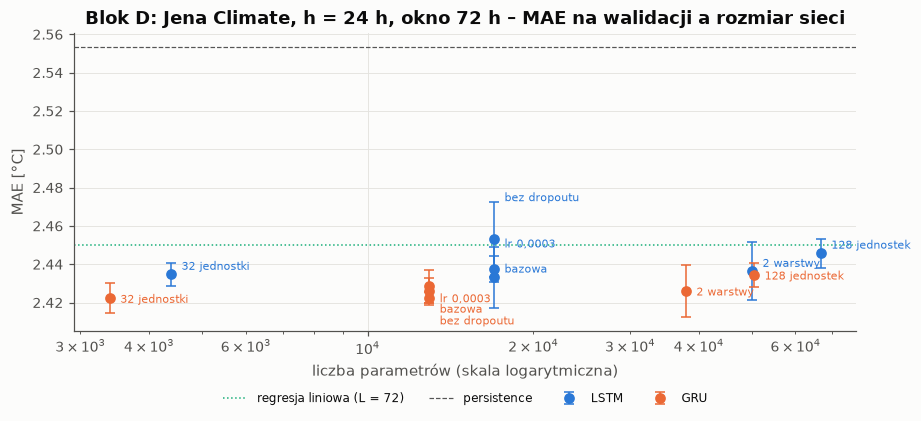

In [17]:
td_ = r3.block_d_table(df, FIG)
fig = r3.plot_block_d(td_, bl, FIG)
display(td_.round(3))

**Komentarz.** Wszystkie warianty dają MAE 2,422–2,453 °C, a żadna różnica względem konfiguracji bazowej nie przekracza rozrzutu między ziarnami. Większe sieci (2 warstwy, 128 jednostek) mają niższy błąd uczący (np. GRU 2,361 wobec 2,416 °C), ale nie walidacyjny, a uczą się 2–4 razy dłużej. Najmniejszy GRU (32 jednostki, 3393 parametry) jest tak samo dobry jak bazowy. W badanym zakresie zmian architektury nie widać więc istotnej poprawy, co sugeruje, że wynik ogranicza bardziej informacja w samej historii temperatury niż pojemność sieci. Zgodnie z tym w bloku C dodanie zmiennych pogodowych obniża MAE do 2,35 °C, czyli bardziej niż jakakolwiek zmiana architektury.

### 7.4. Blok E: TCN (Jena Climate, okno 72 h)

,h,model,parametry,MAE,MAE_sd,RMSE,epoki,s_na_epoke,inferencja_ms
0,1,persistence,NaN,0.655,0.000,0.931,NaN,NaN,NaN
1,1,linreg,NaN,0.404,0.000,0.592,NaN,NaN,NaN
2,1,Dense,6785.0,0.472,0.041,0.651,72.667,0.221,43.41
3,1,LSTM,16961.0,0.411,0.002,0.595,36.667,8.594,116.04
4,1,GRU,12929.0,0.407,0.002,0.590,70.000,8.847,95.71
5,1,TCN,17276.0,0.391,0.002,0.571,93.333,6.321,72.69
6,6,persistence,NaN,3.035,0.000,4.063,NaN,NaN,NaN
7,6,linreg,NaN,1.687,0.000,2.219,NaN,NaN,NaN
8,6,Dense,6785.0,1.638,0.041,2.136,48.333,0.229,42.34
9,6,LSTM,16961.0,1.595,0.051,2.095,75.333,9.251,112.81


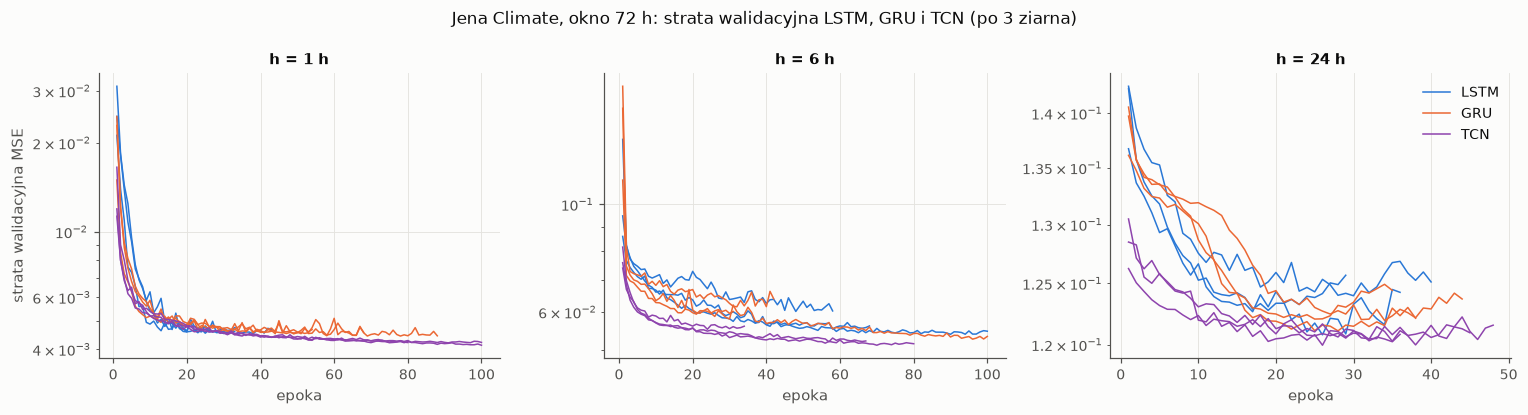

In [18]:
te = r3.block_e_table(df, bl, FIG)
display(te.round(3))
fig = r3.plot_curves_jena_all(df, OUT, FIG)

**Komentarz.** TCN o liczbie parametrów zbliżonej do LSTM (17 276 wobec 16 961) ma najmniejsze MAE spośród modeli porównywanych w warunkach bloku A (okno 72 h, sama historia temperatury) na wszystkich trzech horyzontach: 0,391 °C (h = 1), 1,538 °C (h = 6) i 2,401 °C (h = 24). Przy h = 1 i h = 24 przewaga nad LSTM i GRU jest większa niż rozrzut między ziarnami, przy h = 6 mieści się w ok. jednym odchyleniu. Przy h = 1 TCN jako jedyny wyraźnie wyprzedza regresję liniową (0,404 °C). Krzywe straty walidacyjnej TCN opadają szybciej i są gładsze niż krzywe sieci rekurencyjnych. Przewaga sieci nad metodami prostymi nie jest więc specyficzna dla rekurencji. Dwa treningi TCN przy h = 1 zakończyły się na limicie 100 epok. Czas epoki TCN przy h = 24 (13,7 s) jest ok. dwa razy dłuższy niż przy h = 1 i 6 przy identycznej architekturze, co najpewniej wynika z obciążenia komputera w tym czasie; tego pomiaru nie traktujemy jako wiarygodnego.

### 7.5. Zamrożenie konfiguracji

Zgodnie z Raportem 1 (punkt 12.4) konfigurację wybieramy wyłącznie na walidacji, według najmniejszego średniego MAE z ziaren. Plik `final_configs.json` zawiera dwie grupy dla każdej pary (zbiór, horyzont):

- **„A”** – porównanie w identycznych warunkach bloku A (okno 72 h / 24 mies., tylko historia targetu); wybierany jest tylko wariant przekształcenia Air Passengers,
- **„najlepsza”** – najlepsza konfiguracja każdej rodziny modeli (Dense, LSTM, GRU, TCN i regresja liniowa) ze wszystkich bloków.

Persistence i seasonal naive nie mają parametrów do wyboru. Plik tworzymy poleceniem `python run_experiments.py --zamroz` przed jakimkolwiek użyciem zbioru testowego; ocena testowa (Raport 4) czyta wyłącznie ten plik.

In [19]:
if not (OUT / tm.CONFIG_FILE).exists():
    tm.freeze_configs(OUT)
fr, created = r3.frozen_table(OUT, FIG)
print("final_configs.json utworzono:", created)
display(fr)

final_configs.json utworzono: 2026-11-01 19:53:08


,key,h,model,konfiguracja,val_MAE,val_MAE_sd,ziarna
56,jena,1,linreg,"L = 72, + zmienne pomocnicze",0.3921,0.0000,1
49,jena,1,Dense,"blok A, L = 72",0.4716,0.0412,3
51,jena,1,LSTM,"blok C, L = 72, + zmienne pomocnicze",0.3867,0.0064,3
53,jena,1,GRU,"blok B, L = 168",0.4044,0.0001,3
54,jena,1,TCN,"blok E, L = 72, 25 filtrów, 5 bloków",0.3908,0.0023,3
65,jena,6,linreg,"L = 72, + zmienne pomocnicze",1.5274,0.0000,1
58,jena,6,Dense,"blok A, L = 72",1.6377,0.0415,3
60,jena,6,LSTM,"blok C, L = 72, + zmienne pomocnicze",1.4611,0.0109,3
62,jena,6,GRU,"blok B, L = 168",1.5299,0.0239,3
63,jena,6,TCN,"blok E, L = 72, 25 filtrów, 5 bloków",1.5377,0.0336,3


**Komentarz.** Najlepsze konfiguracje pochodzą z różnych bloków: LSTM ze zmiennymi pomocniczymi (blok C) dla Jena Climate, Metro i Household przy h = 1, GRU z oknem 168 h (blok B) dla Jena Climate, krótkie okna (blok B) dla Air Passengers przy h = 1 i 12, a dla Household przy h = 6 i 24 konfiguracje bazowe z bloku A. Żaden wariant architektury z bloku D nie został wybrany. Wszystkie wybrane konfiguracje mają komplet ziaren. Ocena testowa w Raporcie 4 obejmie obie grupy: grupa „A” odpowiada na pytanie, czy LSTM i GRU są lepsze od modeli bazowych w identycznych warunkach, a grupa „najlepsza” – jak dobre są najlepsze znalezione konfiguracje.